In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Ruta a la carpeta del proyecto (una carpeta "arriba" de notebooks/)
RUTA = ".."

df = pd.read_csv(f"{RUTA}/data/processed/dataset_final.csv")

# El CSV guarda las fechas como texto, así que las convertimos
df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
df["datetime"] = df["datetime"].dt.tz_convert("Europe/Madrid")
df = df.set_index("datetime")

print(df.shape)
print(df.head())


(24783, 2)
                             demanda_mw  temperatura
datetime                                            
2024-01-01 00:00:00+01:00  23352.166667          4.6
2024-01-01 01:00:00+01:00  22610.750000          4.3
2024-01-01 02:00:00+01:00  21386.083333          4.1
2024-01-01 03:00:00+01:00  20141.333333          3.6
2024-01-01 04:00:00+01:00  19354.583333          3.1


In [3]:
# Creo las variables
# La fecha está en el índice, así que usamos df.index
df["hora"] = df.index.hour
df["dia_semana"] = df.index.dayofweek   # 0 = lunes ... 6 = domingo
df["mes"] = df.index.month              # 1 = enero ... 12 = diciembre


/var/folders/ld/g1s837zd4szbbnm9hty5h28c0000gn/T/ipykernel_80877/3690969542.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df["dia_semana"] = df.index.dayofweek   # 0 = lunes ... 6 = domingo


In [4]:
# Creo lags (las demandas del pasado)
# shift(n) desplaza la columna n filas hacia abajo:
# cada fila recibe el valor que había n horas antes
df["demanda_lag_24"] = df["demanda_mw"].shift(24)     # misma hora, el día anterior
df["demanda_lag_168"] = df["demanda_mw"].shift(168)   # misma hora, la semana anterior

print(df[["demanda_mw", "demanda_lag_24", "demanda_lag_168"]].head(30))
print(df.isna().sum())


                             demanda_mw  demanda_lag_24  demanda_lag_168
datetime                                                                
2024-01-01 00:00:00+01:00  23352.166667             NaN              NaN
2024-01-01 01:00:00+01:00  22610.750000             NaN              NaN
2024-01-01 02:00:00+01:00  21386.083333             NaN              NaN
2024-01-01 03:00:00+01:00  20141.333333             NaN              NaN
2024-01-01 04:00:00+01:00  19354.583333             NaN              NaN
2024-01-01 05:00:00+01:00  19074.500000             NaN              NaN
2024-01-01 06:00:00+01:00  19260.083333             NaN              NaN
2024-01-01 07:00:00+01:00  19659.333333             NaN              NaN
2024-01-01 08:00:00+01:00  19698.750000             NaN              NaN
2024-01-01 09:00:00+01:00  20058.166667             NaN              NaN
2024-01-01 10:00:00+01:00  21301.333333             NaN              NaN
2024-01-01 11:00:00+01:00  22539.666667            

In [5]:
# Esta vez si los borramos
df = df.dropna()
print(df.shape)
print(df.isna().sum())


(24615, 7)
demanda_mw         0
temperatura        0
hora               0
dia_semana         0
mes                0
demanda_lag_24     0
demanda_lag_168    0
dtype: int64


Fin de semana

In [6]:
# True si es sábado (5) o domingo (6); .astype(int) lo convierte en 1 / 0
df["es_finde"] = (df["dia_semana"] >= 5).astype(int)
print(df[["dia_semana", "es_finde"]].drop_duplicates().sort_values("dia_semana"))


                           dia_semana  es_finde
datetime                                       
2024-01-08 00:00:00+01:00           0         0
2024-01-09 00:00:00+01:00           1         0
2024-01-10 00:00:00+01:00           2         0
2024-01-11 00:00:00+01:00           3         0
2024-01-12 00:00:00+01:00           4         0
2024-01-13 00:00:00+01:00           5         1
2024-01-14 00:00:00+01:00           6         1


Festivos

In [7]:
import holidays

# Festivos nacionales de España en los años de los datos
festivos_es = holidays.Spain(years=[2024, 2025, 2026])

# Vemos algunos para comprobar
for fecha, nombre in list(festivos_es.items())[:5]:
    print(fecha, nombre)

# 1 si el día es festivo, 0 si no
df["festivo"] = [1 if fecha in festivos_es else 0 for fecha in df.index.date]

print(df["festivo"].sum() / 24, "días festivos")


2024-01-01 Año Nuevo
2024-01-06 Epifanía del Señor
2024-03-29 Viernes Santo
2024-05-01 Fiesta del Trabajo
2024-08-15 Asunción de la Virgen
22.0 días festivos


In [8]:
#creo variables de lag
# Creamos las variables de lag de festivos
df["festivo_lag_24"] = df["festivo"].shift(24)      # ¿ayer fue festivo?
df["festivo_lag_168"] = df["festivo"].shift(168)    # ¿hace una semana fue festivo?

# Nochebuena y Nochevieja: no son festivos oficiales, pero se consume distinto
df["nochebuena_nochevieja"] = ((df.index.month == 12) & (df.index.day.isin([24, 31]))).astype(int)


In [9]:
#creo variables de lag
# Creamos las variables de lag de festivos
df["festivo_lag_24"] = df["festivo"].shift(24)      # ¿ayer fue festivo?
df["festivo_lag_168"] = df["festivo"].shift(168)    # ¿hace una semana fue festivo?

# Nochebuena y Nochevieja: no son festivos oficiales, pero se consume distinto
df["nochebuena_nochevieja"] = ((df.index.month == 12) & (df.index.day.isin([24, 31]))).astype(int)

# Borramos las filas con NaN (las primeras horas, que no tienen "ayer" ni "semana anterior")
df = df.dropna()
print("NaN restantes:", df.isna().sum().sum())


NaN restantes: 0


Apagón

In [10]:
filas_antes = len(df)

# Nos quedamos con todo lo que NO esté entre esas fechas (~ significa "NO")
df = df[~((df.index >= "2025-04-28") & (df.index < "2025-05-06"))]

print("Filas eliminadas:", filas_antes - len(df))   # deberían ser 192 (8 días × 24 h)
#Se excluyen del 28-04-2025 al 05-05-2025

Filas eliminadas: 192


## Separación train / test

Para evaluar el modelo, los datos se dividen en dos partes: una para **entrenar**
y otra para **comprobar** si acierta.

En series temporales **no se puede separar al azar**: el modelo usaría datos del
futuro para predecir el pasado, y los resultados serían falsos.

Por eso separo **por fecha**:

- **Train:** enero 2024 – octubre 2025
- **Test:** noviembre 2025 – octubre 2026

Además, el modelo solo usa la demanda de hace 24 horas y de hace una semana,
porque el objetivo es predecir con un día de antelación.


In [11]:
# Separo la fecha
fecha_corte = "2025-11-01"

train = df[df.index < fecha_corte]
test = df[df.index >= fecha_corte]

print("Train:", train.index.min(), "→", train.index.max(), "|", len(train), "filas")
print("Test: ", test.index.min(), "→", test.index.max(), "|", len(test), "filas")


Train: 2024-01-15 00:00:00+01:00 → 2025-10-31 23:00:00+01:00 | 15552 filas
Test:  2025-11-01 00:00:00+01:00 → 2026-10-29 14:00:00+01:00 | 8703 filas


In [12]:
# 1. Lista con los nombres de las columnas que usará el modelo (las pistas)
features = ["temperatura", "hora", "dia_semana", "mes", "es_finde", "festivo",
            "demanda_lag_24", "demanda_lag_168",
            "festivo_lag_24", "festivo_lag_168", "nochebuena_nochevieja"]

# 2. Nombre de la columna que queremos predecir (la respuesta)
objetivo = "demanda_mw"

# 3. Datos de ENTRENAMIENTO
X_train = train[features]    # tabla con las 11 columnas de pistas
y_train = train[objetivo]

# 4. Datos de TEST
X_test = test[features]
y_test = test[objetivo]

# 5. Comprobamos tamaños
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)



X_train: (15552, 11) | y_train: (15552,)
X_test:  (8703, 11) | y_test:  (8703,)


# ¿ Cómo mido si la predicción es buena?
Usaremos tres métricas. Todas comparan lo que predices con lo que pasó de verdad:

Métrica	Qué significa	Ejemplo


MAE (error absoluto medio)	De media, ¿cuántos MW me equivoco?	MAE = 1.000 → fallo de media por 1.000 MW

MAPE (error porcentual medio)	Lo mismo, pero en %	MAPE = 3% → fallo de media un 3%

RMSE	Como el MAE, pero castiga más los errores grandes	Si es mucho mayor que el MAE, hay días con fallos enormes


---


En todas, cuanto más bajo, mejor. La más fácil de explicar en una entrevista es el MAPE: "mi modelo se equivoca de media un X%".

In [13]:
# El baseline es la predicción más simple posible. Si el modelo de ML no la mejora, no sirve para nada.


from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error

# La "predicción" del baseline es simplemente el valor de hace una semana
pred_baseline = X_test["demanda_lag_168"]

mae = mean_absolute_error(y_test, pred_baseline)
mape = mean_absolute_percentage_error(y_test, pred_baseline) * 100   # ×100 para pasarlo a %
rmse = root_mean_squared_error(y_test, pred_baseline)

print(f"Baseline (semana anterior) → MAE: {mae:.0f} MW | MAPE: {mape:.2f}% | RMSE: {rmse:.0f} MW")


Baseline (semana anterior) → MAE: 1392 MW | MAPE: 4.42% | RMSE: 2074 MW


In [14]:
# Segundo baseline: la demanda será la misma que AYER a la misma hora
pred_baseline_24 = X_test["demanda_lag_24"]

mae_24 = mean_absolute_error(y_test, pred_baseline_24)
mape_24 = mean_absolute_percentage_error(y_test, pred_baseline_24) * 100
rmse_24 = root_mean_squared_error(y_test, pred_baseline_24)

print(f"Baseline (día anterior)  → MAE: {mae_24:.0f} MW | MAPE: {mape_24:.2f}% | RMSE: {rmse_24:.0f} MW")



Baseline (día anterior)  → MAE: 1928 MW | MAPE: 6.21% | RMSE: 2894 MW


**¿Por qué gana el de la semana anterior?**

Por los días de la semana. El baseline del "día anterior" falla mucho en dos momentos:

Lunes: lo predice con el domingo, que tiene demanda baja (corto).
Sábado: lo predice con el viernes, laborable con demanda alta (se pasa).

El de la "semana anterior" compara siempre lunes con lunes y sábado con sábado, así que esquiva ese problema. A esto se le llama estacionalidad semanal: la demanda se repite cada 7 días. ¡Lo habías visto en la gráfica por día de la semana!

El número a batir es MAPE = 4,42%. Si tu modelo no baja de ahí, no aporta nada.



# MODELO

In [15]:
def evaluar(nombre, y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    mape = mean_absolute_percentage_error(y_real, y_pred) * 100
    rmse = root_mean_squared_error(y_real, y_pred)
    print(f"{nombre:25} → MAE: {mae:.0f} MW | MAPE: {mape:.2f}% | RMSE: {rmse:.0f} MW")

# Probamos que funciona con los baselines
evaluar("Baseline semana anterior", y_test, X_test["demanda_lag_168"])
evaluar("Baseline día anterior", y_test, X_test["demanda_lag_24"])


Baseline semana anterior  → MAE: 1392 MW | MAPE: 4.42% | RMSE: 2074 MW
Baseline día anterior     → MAE: 1928 MW | MAPE: 6.21% | RMSE: 2894 MW


In [16]:
from sklearn.linear_model import LinearRegression

# 1. Crear el modelo (vacío, todavía no sabe nada)
modelo_lineal = LinearRegression()

# 2. Entrenar: el modelo aprende la relación entre las pistas (X) y la respuesta (y)
modelo_lineal.fit(X_train, y_train)

# 3. Predecir: le damos las pistas del test y nos devuelve sus predicciones
pred_lineal = modelo_lineal.predict(X_test)

evaluar("Regresión lineal", y_test, pred_lineal)


Regresión lineal          → MAE: 1112 MW | MAPE: 3.54% | RMSE: 1522 MW


In [17]:
# ─── REGRESIÓN LINEAL (lo que ya hice) ───
#modelo_lineal = LinearRegression()                     1. Crear
#modelo_lineal.fit(X_train, y_train)                    2. Entrenar
#pred_lineal = modelo_lineal.predict(X_test)            3. Predecir
#evaluar("Regresión lineal", y_test, pred_lineal)       4. Evaluar

# ─── RANDOM FOREST  ───
from sklearn.ensemble import RandomForestRegressor

modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)   # 1. Crear
modelo_rf.fit(X_train, y_train)                       # 2. Entrenar
pred_rf = modelo_rf.predict(X_test)                   # 3. Predecir
evaluar("Random Forest", y_test, pred_rf)             # 4. Evaluar


Random Forest             → MAE: 933 MW | MAPE: 2.87% | RMSE: 1356 MW


Ahora tratamos de entender el modelo, voy a utilizar 3 analisis cortos

Que variable usa más

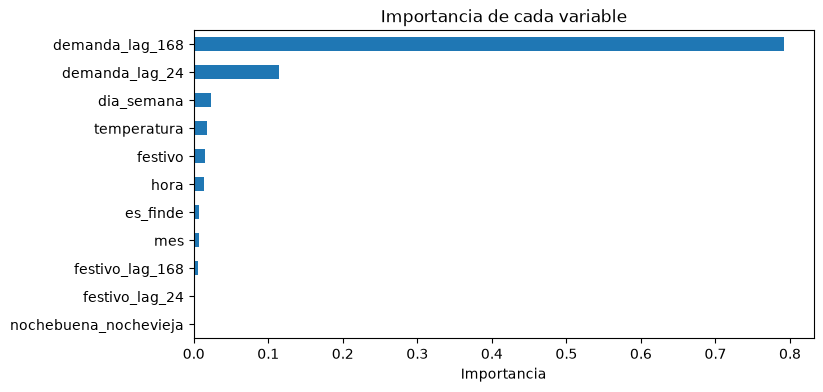

In [18]:
# El Random Forest nos dice cuánto ha usado cada variable
importancias = pd.Series(modelo_rf.feature_importances_, index=features).sort_values()

importancias.plot(kind="barh", figsize=(8, 4), title="Importancia de cada variable")
plt.xlabel("Importancia")
plt.show()


Predicción frente a realidad

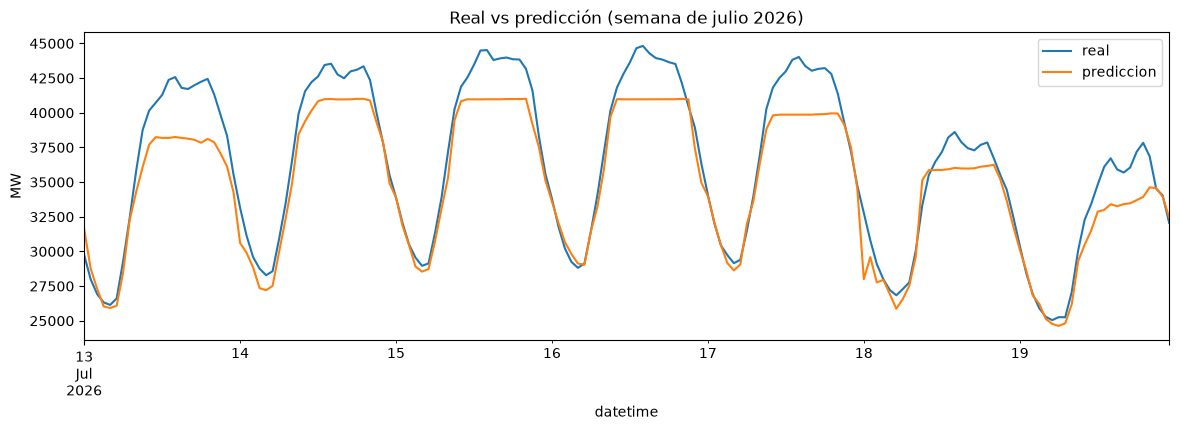

In [19]:
# Juntamos lo real y lo predicho en una tabla para poder graficarlo
resultados = pd.DataFrame({"real": y_test, "prediccion": pred_rf}, index=y_test.index)

resultados.loc["2026-07-13":"2026-07-19"].plot(figsize=(14, 4), title="Real vs predicción (semana de julio 2026)")
plt.ylabel("MW")
plt.show()


En que meses falla mas

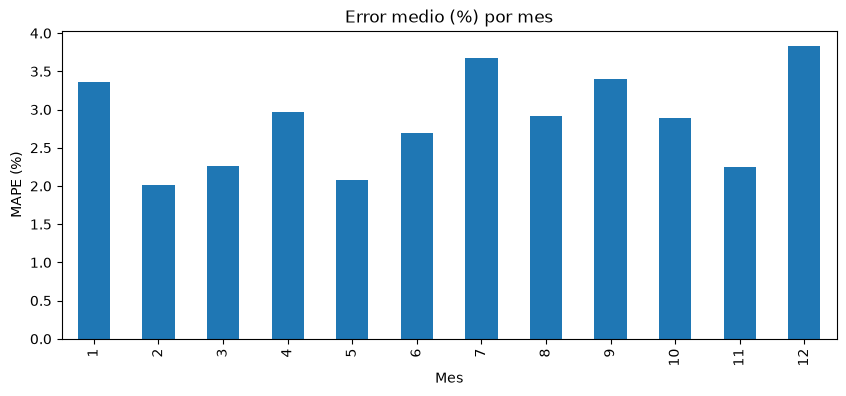

In [20]:
# Error porcentual de cada hora
resultados["error_pct"] = abs(resultados["real"] - resultados["prediccion"]) / resultados["real"] * 100

resultados.groupby(resultados.index.month)["error_pct"].mean().plot(kind="bar", figsize=(10, 4), title="Error medio (%) por mes")
plt.ylabel("MAPE (%)")
plt.xlabel("Mes")
plt.show()


El mes que mas falla es diciembre

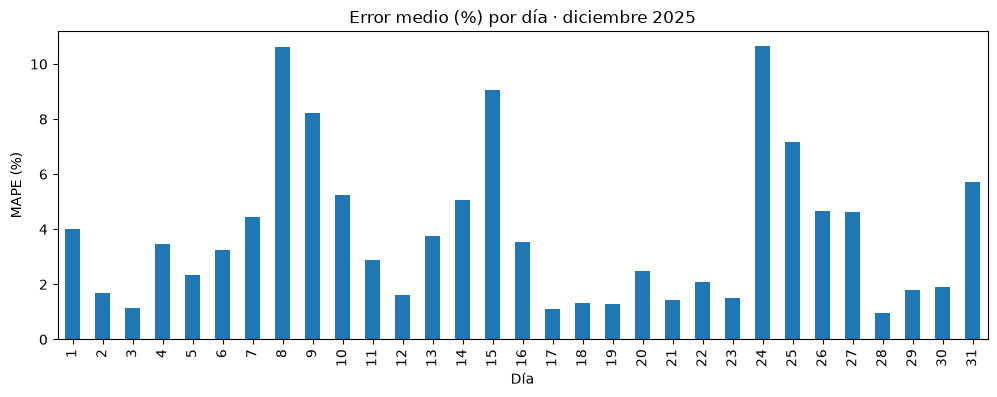

In [21]:
# Error medio por día, solo en diciembre de 2025
dic = resultados.loc["2025-12-01":"2025-12-31"]
dic.groupby(dic.index.day)["error_pct"].mean().plot(kind="bar", figsize=(12, 4), title="Error medio (%) por día · diciembre 2025")
plt.ylabel("MAPE (%)")
plt.xlabel("Día")
plt.show()


Día	Qué era	Error	Explicación
8 (lun)	Festivo (Inmaculada)	8%	Festivo y puente

9 (mar)	Día después del festivo	10,5%

15 (lun)	Una semana después del festivo	7,4% otra vez

24 (mié)	Nochebuena	11,2%	No es festivo oficial, el modelo no lo sabe
25–27	Navidad y puente	5–7%	Vacaciones

31 (mié)	Nochevieja	7%	No es festivo oficial

El lag viene de un festivo

In [22]:
# Comparamos el Random Forest con las variables ANTIGUAS (8) y con las NUEVAS (11), X_train[features_antiguas] coge solo las 8 primeras y deja fuera las 3 nuevas. Es como decirle al modelo: "haz como si las nuevas no existieran".

features_antiguas = ["temperatura", "hora", "dia_semana", "mes", "es_finde", "festivo",
                     "demanda_lag_24", "demanda_lag_168"]

# Modelo 1: solo las 8 variables antiguas
rf_8 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_8.fit(X_train[features_antiguas], y_train)
pred_rf_8 = rf_8.predict(X_test[features_antiguas])

# Modelo 2: las 11 variables (con festivo_lag_24, festivo_lag_168 y nochebuena_nochevieja)
rf_11 = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_11.fit(X_train, y_train)
pred_rf_11 = rf_11.predict(X_test)

evaluar("Random Forest (8 var.)", y_test, pred_rf_8)
evaluar("Random Forest (11 var.)", y_test, pred_rf_11)


Random Forest (8 var.)    → MAE: 943 MW | MAPE: 2.90% | RMSE: 1383 MW
Random Forest (11 var.)   → MAE: 933 MW | MAPE: 2.87% | RMSE: 1356 MW


Hay cambio pero poco, de 2.90 a 2.87, ¿por que ?:

Porque las variables nuevas solo ayudan en unos pocos días al año: festivos, días después de festivos, Nochebuena y Nochevieja. Son unos 20 días de 365

Añadir variables de festivos retardados y de Nochebuena/Nochevieja mejora poco el error global (2,90% → 2,87%), porque afectan a pocos días. Sin embargo, reducen los errores grandes (RMSE −30 MW), concentrados en los periodos festivos.

Entonces compruebo donde importa: diciembre.

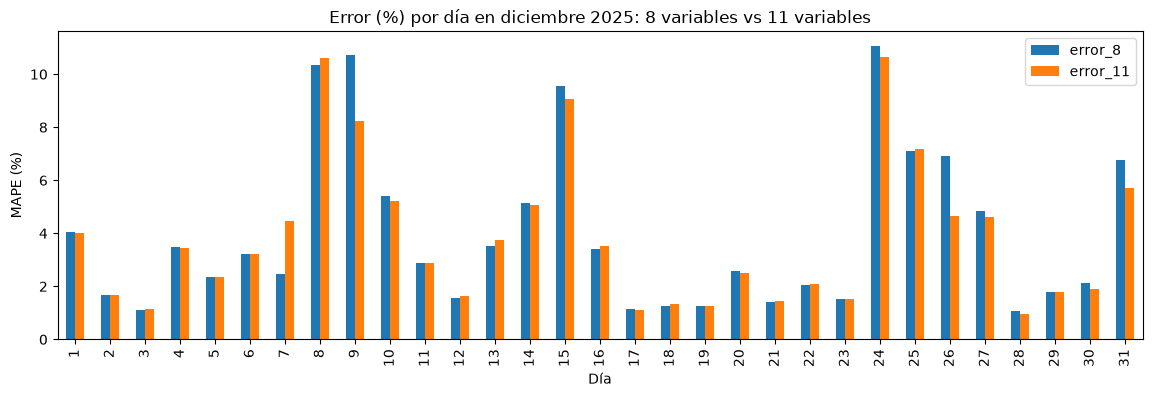

In [23]:
# Comparamos el error por día en diciembre de 2025: antes vs después
comparacion = pd.DataFrame({
    "real": y_test,
    "pred_8": pred_rf_8,
    "pred_11": pred_rf_11
}, index=y_test.index)

comparacion["error_8"] = abs(comparacion["real"] - comparacion["pred_8"]) / comparacion["real"] * 100
comparacion["error_11"] = abs(comparacion["real"] - comparacion["pred_11"]) / comparacion["real"] * 100

dic = comparacion.loc["2025-12-01":"2025-12-31"]
dic.groupby(dic.index.day)[["error_8", "error_11"]].mean().plot(kind="bar", figsize=(14, 4),
    title="Error (%) por día en diciembre 2025: 8 variables vs 11 variables")
plt.ylabel("MAPE (%)")
plt.xlabel("Día")
plt.show()



### Efecto de las variables de festivos

Añadí tres variables: si el día anterior fue festivo, si hace una semana fue
festivo y si es Nochebuena o Nochevieja. El error global apenas cambia
(MAPE 2,90% → 2,87%), porque solo afectan a unos pocos días al año. Pero el
RMSE baja más (1.384 → 1.354 MW), lo que indica que se reducen los errores
grandes.

Analizando diciembre de 2025 día a día:

- **Mejora** en los días posteriores a un festivo: 9 dic (10,6% → 8,2%) y
  26 dic (6,8% → 4,6%). También en Nochevieja (6,6% → 5,6%).
- **Empeora** el 7 dic (2,4% → 4,6%): el festivo anterior cayó en sábado y el
  modelo corrige de más, aunque un festivo en fin de semana apenas cambia la
  demanda.
- **No mejora** en los propios festivos (8 dic, ~10,5%) ni en Nochebuena
  (~11%). En el histórico de entrenamiento solo hay una Nochebuena, y el modelo
  no puede aprender bien un evento que ha visto una sola vez.

Los días festivos siguen siendo la principal fuente de error. Con más años de
histórico, o con una variable que distinga los festivos que caen en fin de
semana, el modelo podría mejorar en estos días.


In [24]:
# Guardo resultados
import os

# Carpetas donde guardaremos las imágenes y las tablas para el README
os.makedirs(f"{RUTA}/reports/figures", exist_ok=True)
CARPETA_FIG = f"{RUTA}/reports/figures"
print("Carpetas listas ")


Carpetas listas 


### Tabla comparativa de modelos


In [25]:
# Calculamos las métricas de cada modelo y las guardamos en una tabla
def metricas(y_real, y_pred):
    return {
        "MAE (MW)": round(mean_absolute_error(y_real, y_pred)),
        "MAPE (%)": round(mean_absolute_percentage_error(y_real, y_pred) * 100, 2),
        "RMSE (MW)": round(root_mean_squared_error(y_real, y_pred)),
    }

tabla_resultados = pd.DataFrame({
    "Baseline día anterior": metricas(y_test, X_test["demanda_lag_24"]),
    "Baseline semana anterior": metricas(y_test, X_test["demanda_lag_168"]),
    "Regresión lineal": metricas(y_test, pred_lineal),
    "Random Forest (8 var.)": metricas(y_test, pred_rf_8),
    "Random Forest (11 var.)": metricas(y_test, pred_rf_11),
}).T   # .T le da la vuelta a la tabla: modelos en filas, métricas en columnas

print(tabla_resultados)
tabla_resultados.to_csv(f"{RUTA}/reports/resultados_modelos.csv")


                          MAE (MW)  MAPE (%)  RMSE (MW)
Baseline día anterior       1928.0      6.21     2894.0
Baseline semana anterior    1392.0      4.42     2074.0
Regresión lineal            1112.0      3.54     1522.0
Random Forest (8 var.)       943.0      2.90     1383.0
Random Forest (11 var.)      933.0      2.87     1356.0


### Gráficas para el README


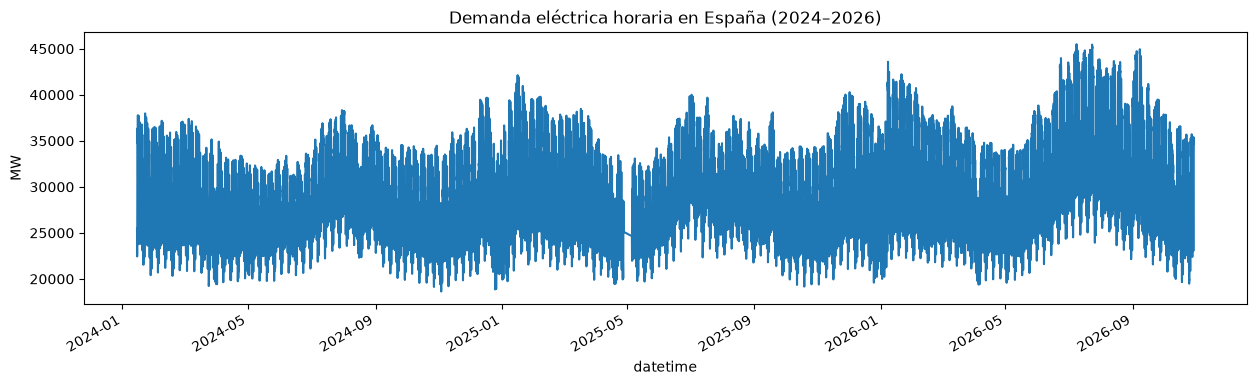

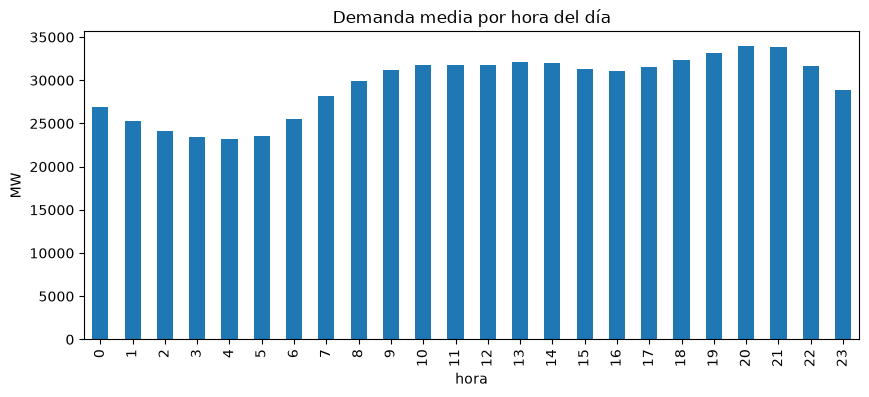

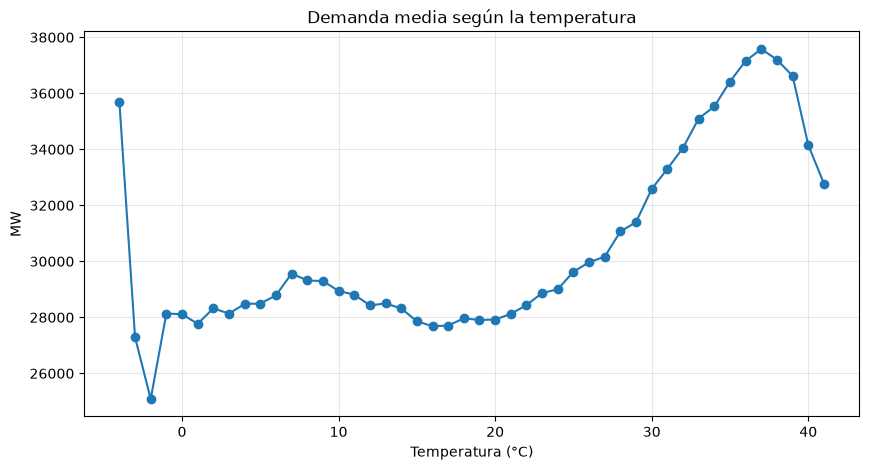

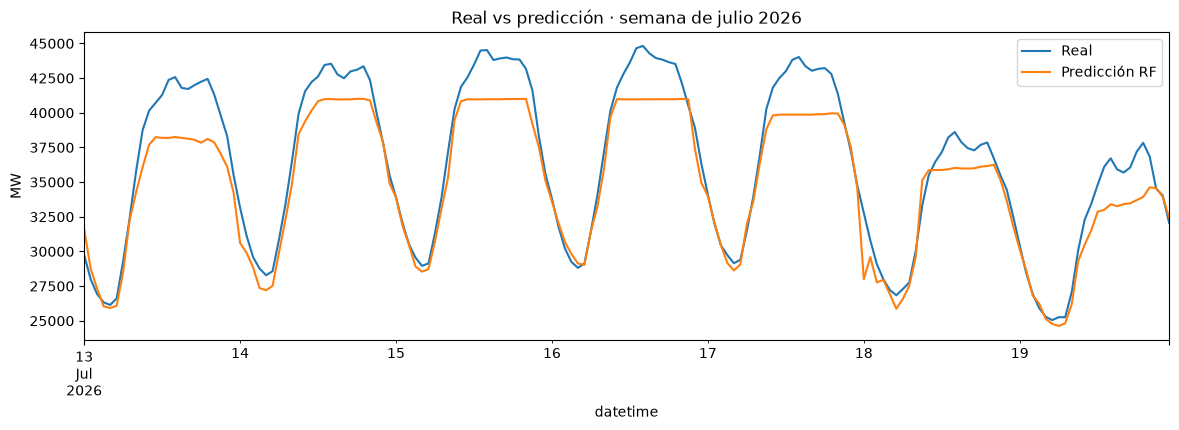

In [26]:
# 1. Serie completa
df["demanda_mw"].plot(figsize=(15, 4), title="Demanda eléctrica horaria en España (2024–2026)")
plt.ylabel("MW")
plt.savefig(f"{CARPETA_FIG}/01_serie_completa.png", dpi=120, bbox_inches="tight")
plt.show()

# 2. Demanda media por hora
df.groupby("hora")["demanda_mw"].mean().plot(kind="bar", figsize=(10, 4), title="Demanda media por hora del día")
plt.ylabel("MW")
plt.savefig(f"{CARPETA_FIG}/02_demanda_por_hora.png", dpi=120, bbox_inches="tight")
plt.show()

# 3. Demanda frente a temperatura (la U)
df.groupby(df["temperatura"].round())["demanda_mw"].mean().plot(marker="o", figsize=(10, 5),
    title="Demanda media según la temperatura")
plt.xlabel("Temperatura (°C)")
plt.ylabel("MW")
plt.grid(alpha=0.3)
plt.savefig(f"{CARPETA_FIG}/03_demanda_vs_temperatura.png", dpi=120, bbox_inches="tight")
plt.show()

# 4. Real vs predicción (una semana de julio)
pd.DataFrame({"Real": y_test, "Predicción RF": pred_rf_11}, index=y_test.index) \
  .loc["2026-07-13":"2026-07-19"].plot(figsize=(14, 4), title="Real vs predicción · semana de julio 2026")
plt.ylabel("MW")
plt.savefig(f"{CARPETA_FIG}/04_real_vs_prediccion.png", dpi=120, bbox_inches="tight")
plt.show()
